In [1]:

!pip install -q kagglehub

import kagglehub
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully!")



Libraries imported successfully!


In [2]:

# Download the Kaggle Mudra dataset

path = kagglehub.dataset_download(
    "geethikanambiar/mudra-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset path:", path)

# Inspect the dataset directory structure
for root, dirs, files in os.walk(path):
    depth = len(Path(root).relative_to(path).parts)
    if depth > 3:
        dirs[:] = []
        continue

    print("  " * depth + os.path.basename(root) + "/")
    for name in files[:5]:
        print("  " * (depth + 1) + name)


100%|██████████| 10.2G/10.2G [02:14<00:00, 81.5MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset path: /root/.cache/kagglehub/datasets/geethikanambiar/mudra-dataset/versions/1
1/
  Bharatantyam Mudras/
    chaduram/
      image_1 (32).png
      image_1 (28).png
      image_1 (36).png
      image_1 (19).png
      image_1 (13).png
    Shivalinga/
      Shivalinga _34.jpg
      Shivalinga _6.jpg
      Shivalinga _20.jpg
      Shivalinga _5.jpg
      Shivalinga _8.jpg
    pathaka/
      image_1 (32).png
      WhatsApp Image 2024-09-24 at 14.41.36_3a1a5f92.jpg
      image_1 (28).png
      image_1 (36).png
      image_1 (19).png
    Bherundha/
      Berunda  _24.jpg
      Berunda  _33.jpg
      Berunda  _26.jpg
      Berunda  _31.jpg
      Berunda  _16.jpg
    trishoolam/
      image_1 (32).png
      image_1 (28).png
      image_1 (36).png
      image_1 (19).png
      image_1 (13).png
    Karkidakam/
      Karkatta _4.jpg
      Karkatta _11.jpg
      Karkatta _39.jpg
      Karkatta _3.jpg
      Karkatta _0.jpg
    Matsya/
      Matsya  _42.jpg
  

In [3]:

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_paths = [
    p for p in Path(path).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total image files found:", len(image_paths))

records = []

for img_path in image_paths:
    try:
        with Image.open(img_path) as img:
            width, height = img.size
            mode = img.mode

        records.append({
            "filepath": str(img_path),
            "class": img_path.parent.name,
            "width": width,
            "height": height,
            "color_mode": mode,
            "aspect_ratio": width / height
        })

    except Exception as e:
        print("Unreadable image:", img_path, e)

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "No readable images found. Check dataset format."
    )

print("\nDataset preview:")
display(df.head())

print("\nDetected classes:")
print(df["class"].value_counts())

print("\nNumber of detected classes:",
      df["class"].nunique())


Total image files found: 2441

Dataset preview:


,filepath,class,width,height,color_mode,aspect_ratio
0,/root/.cache/kagglehub/datasets/geethikanambia...,chaduram,2604,4624,RGB,0.563149
1,/root/.cache/kagglehub/datasets/geethikanambia...,chaduram,2604,4624,RGB,0.563149
2,/root/.cache/kagglehub/datasets/geethikanambia...,chaduram,2604,4624,RGB,0.563149
3,/root/.cache/kagglehub/datasets/geethikanambia...,chaduram,2604,4624,RGB,0.563149
4,/root/.cache/kagglehub/datasets/geethikanambia...,chaduram,2604,4624,RGB,0.563149



Detected classes:
class
chaduram             50
Shivalinga           50
pathaka              50
Bherundha            50
trishoolam           50
Karkidakam           50
Matsya               50
mrigasheersham       50
Garuda               50
Paasha               50
soochi               50
alapadmam            50
hamsapaksham         50
sarpashirasu         50
Shakatam             50
mukulam              50
mayooram             50
bramaram             50
hamsasyam            50
simhamugham          50
Koorma               50
mushti               50
Pushpapuda           50
Kartaree swastika    50
tamrachoodam         50
arthachandran        50
Khatva               50
Samputa              50
kapitham             50
arthapataka          50
shikaram             50
shukathundam         50
kadakhamukham        50
Anjali               50
Chakra               50
Varaha               50
tripathaka           50
Keelaka              50
kartharimukaham      50
Swasthikam           50
samdhamsham    

In [4]:

all_classes = sorted(df["class"].unique())

print("Available classes:")
for i, cls in enumerate(all_classes, start=1):
    print(f"{i}. {cls}")

if len(all_classes) < 5:
    raise ValueError(
        "Fewer than five classes detected. "
        "Check the dataset folder structure."
    )

# If exactly five classes exist, use all five.
# Otherwise select five explicitly after inspecting
# the printed class names.

if len(all_classes) == 5:
    selected_classes = all_classes
else:
    # Replace these with five appropriate class names
    # from the output above.
    selected_classes = all_classes[:5]
    print(
        "\nWARNING: First five alphabetic classes selected. "
        "Review and change selected_classes if needed."
    )

df = df[df["class"].isin(selected_classes)].copy()
df = df.reset_index(drop=True)

print("\nSelected mudra classes:", selected_classes)
print("Total selected images:", len(df))


Available classes:
1. Anjali
2. Bherundha
3. Chakra
4. Garuda
5. Kadakhavarthanm
6. Kapodham
7. Karkidakam
8. Kartaree swastika
9. Keelaka
10. Khatva
11. Koorma
12. Matsya
13. Nagabanda
14. Paasha
15. Pushpapuda
16. Samputa
17. Shakatam
18. Shankha
19. Shivalinga
20. Swasthikam
21. Varaha
22. alapadmam
23. aralam
24. arthachandran
25. arthapataka
26. bramaram
27. chaduram
28. chandrakala
29. hamsapaksham
30. hamsasyam
31. kadakhamukham
32. kangulam
33. kapitham
34. kartharimukaham
35. mayooram
36. mrigasheersham
37. mukulam
38. mushti
39. padmakosham
40. pathaka
41. samdhamsham
42. sarpashirasu
43. shikaram
44. shukathundam
45. simhamugham
46. soochi
47. tamrachoodam
48. tripathaka
49. trishoolam


Selected mudra classes: ['Anjali', 'Bherundha', 'Chakra', 'Garuda', 'Kadakhavarthanm']
Total selected images: 250


,Mudra Class,Image Count,Percentage
0,Anjali,50,20.0
1,Bherundha,50,20.0
2,Chakra,50,20.0
3,Garuda,50,20.0
4,Kadakhavarthanm,50,20.0


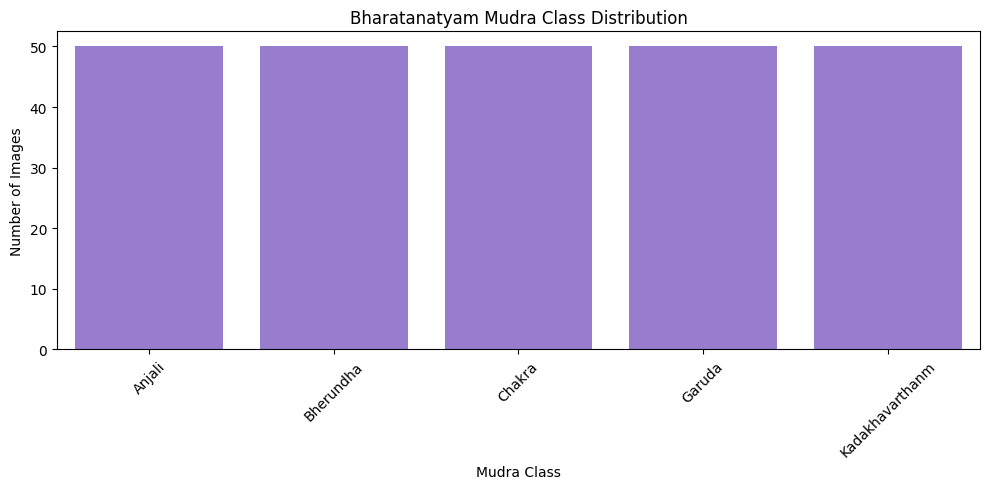

Class imbalance ratio: 1.0
Class percentages:
       Mudra Class  Image Count  Percentage
0           Anjali           50        20.0
1        Bherundha           50        20.0
2           Chakra           50        20.0
3           Garuda           50        20.0
4  Kadakhavarthanm           50        20.0


In [5]:

class_counts = df["class"].value_counts().sort_index()

distribution = pd.DataFrame({
    "Mudra Class": class_counts.index,
    "Image Count": class_counts.values,
    "Percentage": (
        class_counts.values / len(df) * 100
    ).round(2)
})

display(distribution)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribution,
    x="Mudra Class",
    y="Image Count",
    color="mediumpurple"
)

plt.title("Bharatanatyam Mudra Class Distribution")
plt.xlabel("Mudra Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

imbalance_ratio = (
    class_counts.max() / class_counts.min()
)

print("Class imbalance ratio:",
      round(imbalance_ratio, 2))

print("Class percentages:")
print(distribution)


Image Size Statistics:


,width,height,aspect_ratio
count,250.0,250.0,2.500000e+02
mean,666.0,500.0,1.332000e+00
std,0.0,0.0,5.117271e-15
min,666.0,500.0,1.332000e+00
25%,666.0,500.0,1.332000e+00
50%,666.0,500.0,1.332000e+00
75%,666.0,500.0,1.332000e+00
max,666.0,500.0,1.332000e+00



Color Modes:


,count
color_mode,
RGB,250


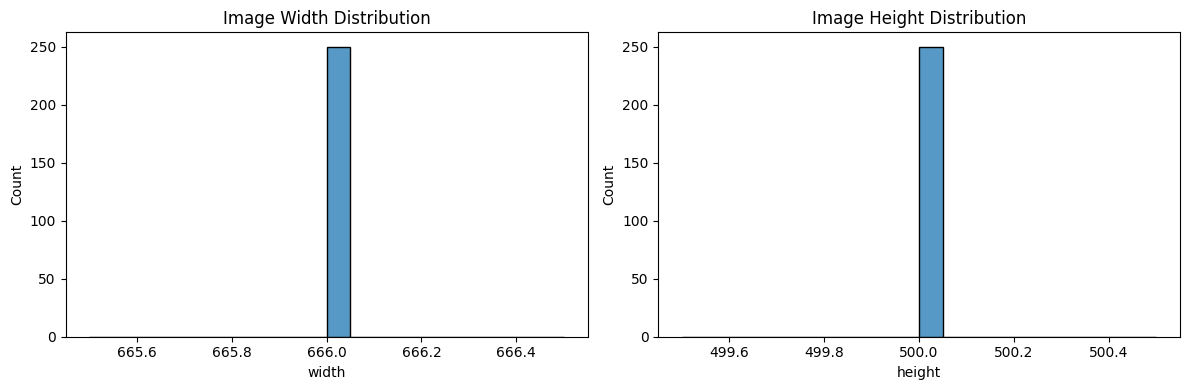

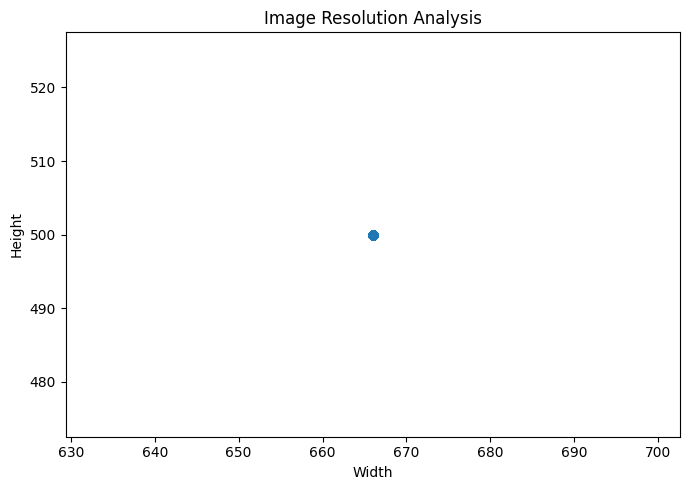

In [6]:

print("Image Size Statistics:")
display(df[["width", "height", "aspect_ratio"]].describe())

print("\nColor Modes:")
display(df["color_mode"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    df["width"],
    bins=20,
    ax=axes[0]
)
axes[0].set_title("Image Width Distribution")

sns.histplot(
    df["height"],
    bins=20,
    ax=axes[1]
)
axes[1].set_title("Image Height Distribution")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(
    df["width"],
    df["height"],
    alpha=0.5
)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Resolution Analysis")
plt.tight_layout()
plt.show()


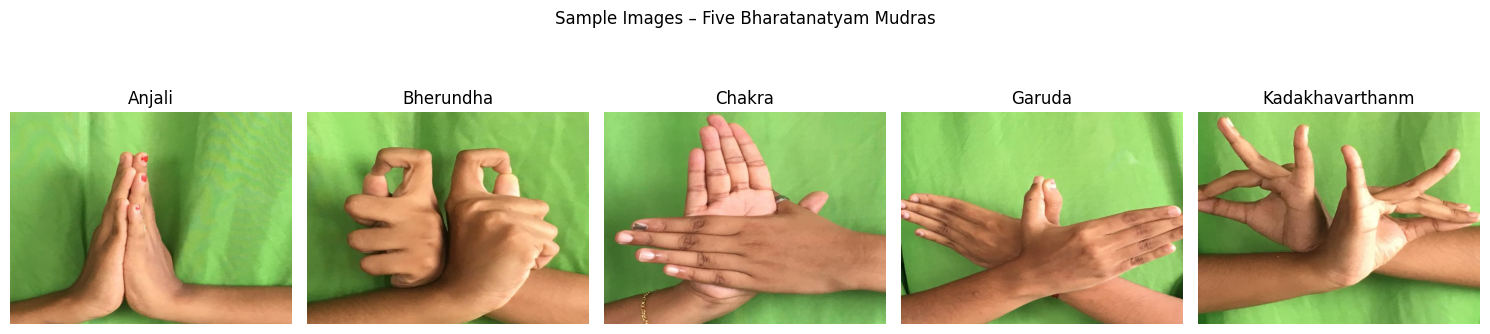

In [7]:

fig, axes = plt.subplots(
    1, len(selected_classes),
    figsize=(15, 4)
)

axes = np.atleast_1d(axes)

for i, cls in enumerate(selected_classes):

    sample = df[df["class"] == cls].sample(
        1, random_state=RANDOM_STATE
    )

    img_path = sample["filepath"].iloc[0]

    with Image.open(img_path) as img:
        axes[i].imshow(img.convert("RGB"))

    axes[i].set_title(cls)
    axes[i].axis("off")

plt.suptitle(
    "Sample Images – Five Bharatanatyam Mudras"
)
plt.tight_layout()
plt.show()


In [8]:

# Check minimum images per class
print(df["class"].value_counts())

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class"],
    random_state=42
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Number of Images": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Percentage": [
        round(len(train_df)/len(df)*100, 2),
        round(len(val_df)/len(df)*100, 2),
        round(len(test_df)/len(df)*100, 2)
    ]
})

display(split_summary)


class
Bherundha          50
Garuda             50
Chakra             50
Anjali             50
Kadakhavarthanm    50
Name: count, dtype: int64
Training images: 175
Validation images: 37
Testing images: 38


,Dataset,Number of Images,Percentage
0,Training,175,70.0
1,Validation,37,14.8
2,Testing,38,15.2


,Training,Validation,Testing
class,,,
Anjali,35,7,8
Bherundha,35,8,7
Chakra,35,7,8
Garuda,35,7,8
Kadakhavarthanm,35,8,7


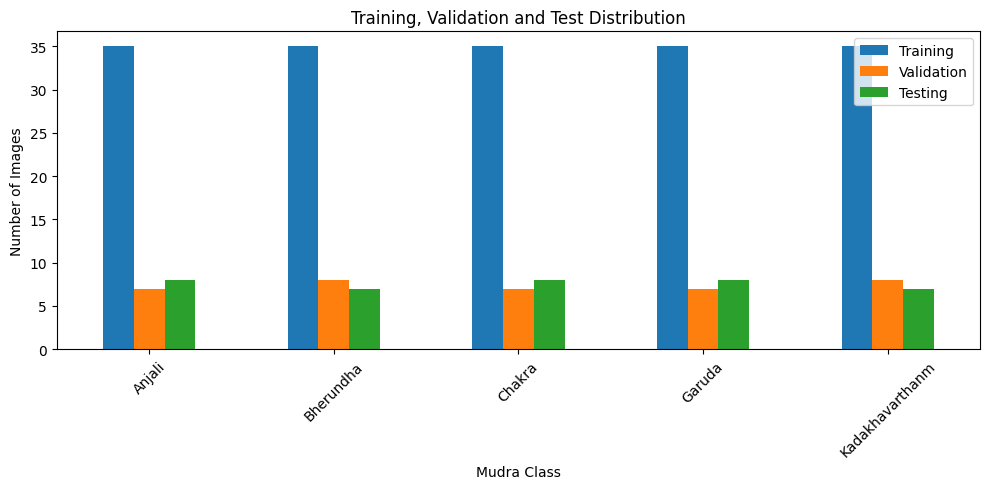

In [9]:

split_counts = pd.DataFrame({
    "Training": train_df["class"].value_counts(),
    "Validation": val_df["class"].value_counts(),
    "Testing": test_df["class"].value_counts()
}).fillna(0).astype(int)

display(split_counts)

split_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Training, Validation and Test Distribution")
plt.xlabel("Mudra Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:

output_dir = "/content/mudra_project"
os.makedirs(output_dir, exist_ok=True)

train_df.to_csv(
    f"{output_dir}/train.csv", index=False
)

val_df.to_csv(
    f"{output_dir}/validation.csv", index=False
)

test_df.to_csv(
    f"{output_dir}/test.csv", index=False
)

print("Dataset split files saved!")
print("Output folder:", output_dir)


Dataset split files saved!
Output folder: /content/mudra_project


In [11]:

counts = df["class"].value_counts()
ratio = counts.max() / counts.min()

print("TASK 1 – DATASET ANALYSIS RESULTS")
print("-" * 45)
print("Total Images:", len(df))
print("Number of Classes:", len(counts))
print("Mudra Classes:", ", ".join(sorted(counts.index)))
print("Minimum Images per Class:", counts.min())
print("Maximum Images per Class:", counts.max())
print("Imbalance Ratio:", round(ratio, 2))

# A practical descriptive threshold, not a formal test
if ratio <= 1.20:
    balance_status = "Approximately balanced"
else:
    balance_status = "Imbalanced"

print("Dataset Balance:", balance_status)

print("\nImage Width Range:",
      df["width"].min(), "-", df["width"].max())
print("Image Height Range:",
      df["height"].min(), "-", df["height"].max())

print("\nTraining:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


TASK 1 – DATASET ANALYSIS RESULTS
---------------------------------------------
Total Images: 250
Number of Classes: 5
Mudra Classes: Anjali, Bherundha, Chakra, Garuda, Kadakhavarthanm
Minimum Images per Class: 50
Maximum Images per Class: 50
Imbalance Ratio: 1.0
Dataset Balance: Approximately balanced

Image Width Range: 666 - 666
Image Height Range: 500 - 500

Training: 175
Validation: 37
Testing: 38


. Is the dataset balanced? How might imbalance affect learning?
Class distribution analysis is essential to ensure fair learning and reliable classification performance across all five mudras.

What image characteristics could make mudra recognition difficult?
The major challenges include differences in hand orientation, lighting, camera angle, image resolution, background complexity, skin tone, and partial finger occlusion.

Small variations in finger positions can represent different mudras, making fine-grained feature extraction important.

These challenges can be addressed through representative training images, consistent preprocessing, careful data augmentation, and CNN-based feature learning.

Would increasing image resolution always improve performance? Justify.
No. Increasing image resolution does not always improve CNN classification performance.


Higher resolution may introduce unnecessary background details and noise without improving classification accuracy.

**Task 2 – Image Preprocessing & Augmentation**

In [12]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)


TensorFlow version: 2.21.0
Image size: (224, 224)
Batch size: 32


Original image shape: (500, 666, 3)
Resized image shape: (224, 224, 3)
Normalized shape: (224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


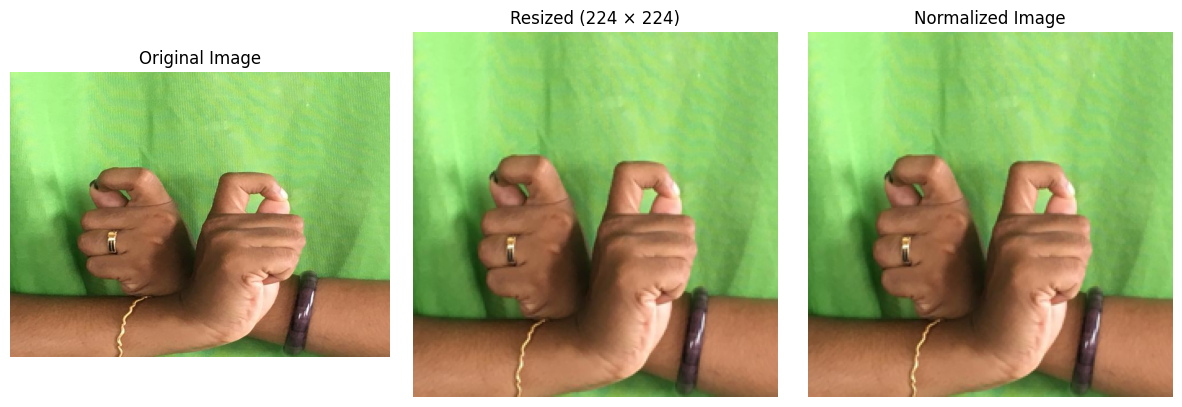

In [13]:

# Select one image from the training dataset
sample_path = train_df.iloc[0]["filepath"]

with Image.open(sample_path) as img:
    original_img = img.convert("RGB")
    resized_img = original_img.resize(IMG_SIZE)

original_array = np.array(original_img)
resized_array = np.array(resized_img)

# Normalize pixel values to [0, 1]
normalized_img = resized_array.astype("float32") / 255.0

print("Original image shape:", original_array.shape)
print("Resized image shape:", resized_array.shape)
print("Normalized shape:", normalized_img.shape)
print("Minimum pixel value:", normalized_img.min())
print("Maximum pixel value:", normalized_img.max())

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original_img)
axes[0].set_title("Original Image")

axes[1].imshow(resized_img)
axes[1].set_title("Resized (224 × 224)")

axes[2].imshow(normalized_img)
axes[2].set_title("Normalized Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [14]:

class_names = sorted(selected_classes)

class_to_index = {
    name: i for i, name in enumerate(class_names)
}

print("Class mapping:", class_to_index)

def load_image(filepath, label):
    image = tf.io.read_file(filepath)

    # Supports JPEG, PNG, BMP and GIF.
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

def make_dataset(dataframe, shuffle=False):
    paths = dataframe["filepath"].astype(str).values

    labels = dataframe["class"].map(
        class_to_index
    ).astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


Class mapping: {'Anjali': 0, 'Bherundha': 1, 'Chakra': 2, 'Garuda': 3, 'Kadakhavarthanm': 4}
Training batches: 6
Validation batches: 2
Testing batches: 2


In [15]:

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(
        factor=0.05,
        fill_mode="nearest"
    ),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="nearest"
    ),

    layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="nearest"
    ),

    layers.RandomContrast(
        factor=0.10
    ),

    layers.RandomBrightness(
        factor=0.10,
        value_range=(0.0, 1.0)
    )
], name="mudra_augmentation")

print("Augmentation pipeline created successfully.")


Augmentation pipeline created successfully.


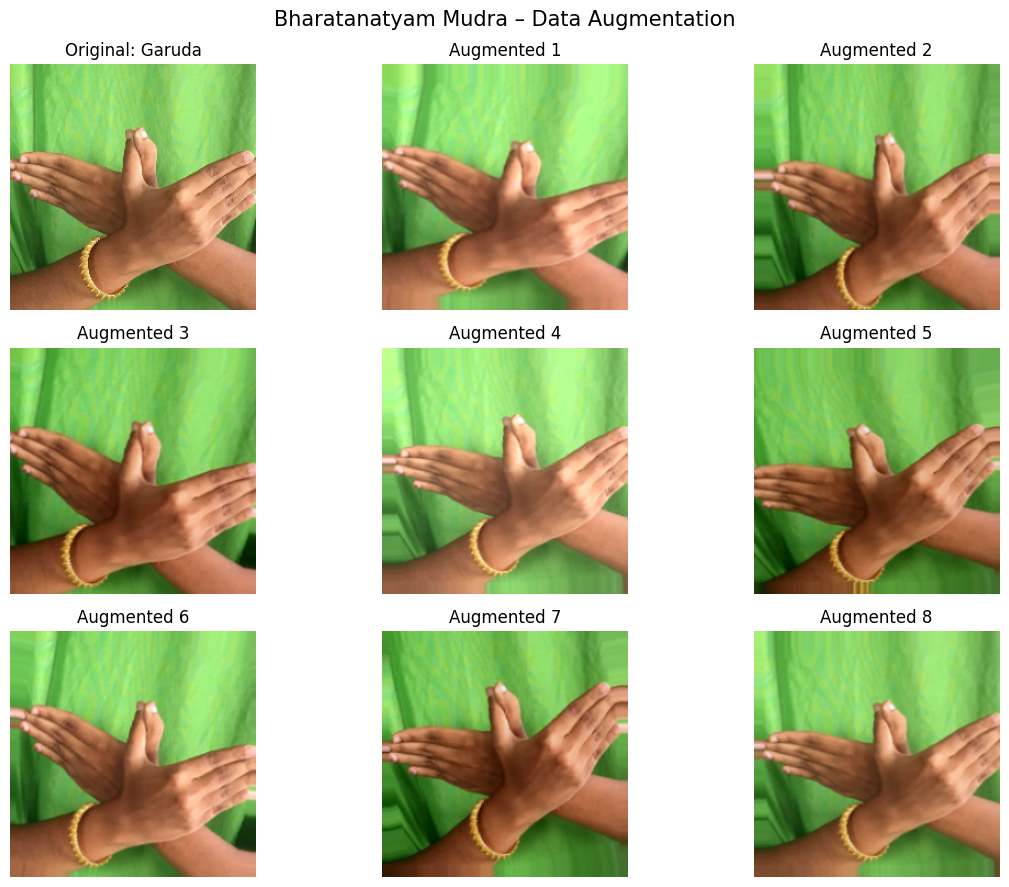

In [16]:

# Take one image from training data
for images, labels in train_ds.take(1):
    sample_image = images[0]
    sample_label = labels[0]

plt.figure(figsize=(12, 9))

# Display original image
plt.subplot(3, 3, 1)
plt.imshow(sample_image.numpy())
plt.title(
    "Original: " +
    class_names[int(sample_label.numpy())]
)
plt.axis("off")

# Generate 8 augmented images
for i in range(8):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    augmented_image = tf.clip_by_value(
        augmented_image, 0.0, 1.0
    )

    plt.subplot(3, 3, i + 2)
    plt.imshow(augmented_image.numpy())
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle(
    "Bharatanatyam Mudra – Data Augmentation",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [17]:

for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:",
          float(tf.reduce_min(images)))

    print("Maximum pixel value:",
          float(tf.reduce_max(images)))

    print("Data type:", images.dtype)

    print("Sample labels:",
          labels[:10].numpy())


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: <dtype: 'float32'>
Sample labels: [1 4 2 1 2 1 4 4 0 2]


In [18]:

# Augmentation is applied inside the CNN model in Task 3.
# Keep train_ds, val_ds, and test_ds unchanged.

for images, labels in train_ds.take(1):
    augmented_batch = data_augmentation(
        images,
        training=True
    )

    print("Original batch:", images.shape)
    print("Augmented batch:", augmented_batch.shape)

print("Datasets ready for CNN training.")


Original batch: (32, 224, 224, 3)
Augmented batch: (32, 224, 224, 3)
Datasets ready for CNN training.


1. Which augmentation techniques preserve the semantic meaning of hand
gestures?

Controlled geometric and photometric augmentations can improve model robustness while retaining important mudra features such as finger positions, hand contours, and gesture structure.

Which augmentations could negatively impact classification accuracy, and
why?
Augmentation should be carefully controlled to preserve the defining characteristics of each Bharatanatyam mudra. Visually inspecting augmented samples is important before CNN training.

**Task 3:CNN Development**


In [19]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("TensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices("GPU"))
print("Classes:", class_names)


TensorFlow Version: 2.21.0
GPU Devices: []
Classes: ['Anjali', 'Bherundha', 'Chakra', 'Garuda', 'Kadakhavarthanm']


In [20]:

def build_cnn(
    learning_rate=0.001,
    dropout_rate=0.3
):

    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        # Data augmentation only during training
        data_augmentation,

        # First convolution block
        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Second convolution block
        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Third convolution block
        layers.Conv2D(
            128, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Fourth convolution block
        layers.Conv2D(
            256, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Classification layers
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(dropout_rate),

        # Five mudra classes
        layers.Dense(
            len(class_names),
            activation="softmax"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = build_cnn()

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mudra_augmentation (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,877 (1.62 MB)

 Trainable params: 422,917 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [21]:

import os

os.makedirs("/content/mudra_project", exist_ok=True)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        "/content/mudra_project/best_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks,
    verbose=1
)

print("CNN training completed!")


Epoch 1/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 51s 7s/step - accuracy: 0.3886 - loss: 1.5766 - val_accuracy: 0.2162 - val_loss: 1.6048 - learning_rate: 0.0010
Epoch 2/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 78s 7s/step - accuracy: 0.5543 - loss: 1.1027 - val_accuracy: 0.1892 - val_loss: 1.6095 - learning_rate: 0.0010
Epoch 3/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 41s 7s/step - accuracy: 0.6914 - loss: 0.8922 - val_accuracy: 0.1892 - val_loss: 1.6301 - learning_rate: 0.0010
Epoch 4/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 84s 7s/step - accuracy: 0.7886 - loss: 0.7323 - val_accuracy: 0.1892 - val_loss: 1.6912 - learning_rate: 0.0010
Epoch 5/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 90s 9s/step - accuracy: 0.8629 - loss: 0.6005 - val_accuracy: 0.1892 - val_loss: 1.7499 - learning_rate: 5.0000e-04
Epoch 6/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 42s 7s/step - accuracy: 0.9086 - loss: 0.4874 - val_accuracy: 0.1892 - val_loss: 1.8545 - learning_rate: 5.0000e-04
CNN training completed!


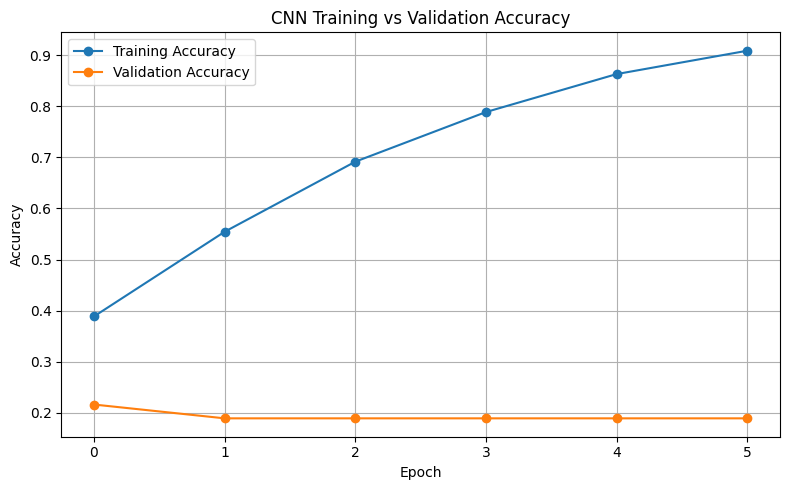

In [22]:

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


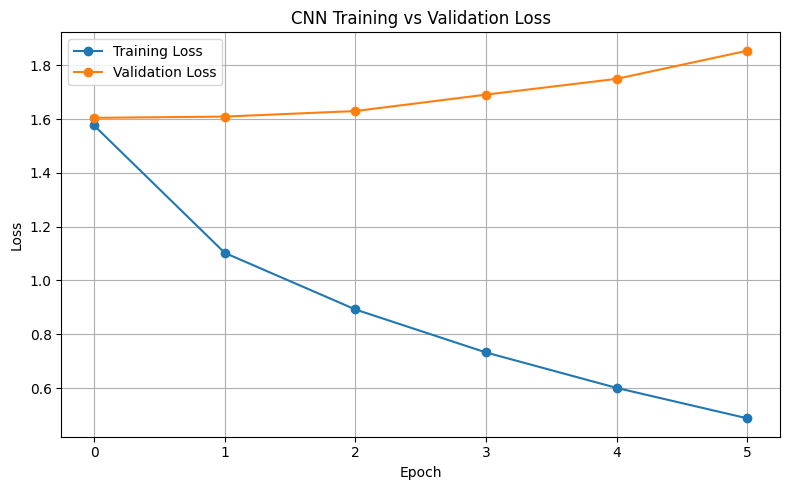

In [23]:

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [24]:

import gc

learning_rates = [0.001, 0.0001]
dropout_rates = [0.3, 0.5]

results = []

best_val_accuracy = -1
best_config = None

for lr in learning_rates:
    for dropout in dropout_rates:

        print("\nTraining Configuration:")
        print("Learning Rate:", lr)
        print("Dropout Rate:", dropout)

        tf.keras.backend.clear_session()

        tuning_model = build_cnn(
            learning_rate=lr,
            dropout_rate=dropout
        )

        tuning_history = tuning_model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=12,
            callbacks=[
                EarlyStopping(
                    monitor="val_loss",
                    patience=3,
                    restore_best_weights=True
                )
            ],
            verbose=1
        )

        val_loss, val_accuracy = tuning_model.evaluate(
            val_ds,
            verbose=0
        )

        results.append({
            "Learning Rate": lr,
            "Dropout Rate": dropout,
            "Validation Accuracy": val_accuracy,
            "Validation Loss": val_loss
        })

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_config = {
                "learning_rate": lr,
                "dropout_rate": dropout
            }

        del tuning_model
        gc.collect()

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Validation Accuracy",
        ascending=False
    )
)

print("Best Configuration:", best_config)
print("Best Validation Accuracy:", best_val_accuracy)



Training Configuration:
Learning Rate: 0.001
Dropout Rate: 0.3
Epoch 1/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 57s 8s/step - accuracy: 0.3429 - loss: 1.5128 - val_accuracy: 0.1892 - val_loss: 1.6111
Epoch 2/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 42s 7s/step - accuracy: 0.6057 - loss: 1.0484 - val_accuracy: 0.1892 - val_loss: 1.6079
Epoch 3/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 42s 7s/step - accuracy: 0.6914 - loss: 0.8600 - val_accuracy: 0.1892 - val_loss: 1.6411
Epoch 4/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 83s 7s/step - accuracy: 0.7771 - loss: 0.6734 - val_accuracy: 0.1892 - val_loss: 1.7120
Epoch 5/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 81s 7s/step - accuracy: 0.8229 - loss: 0.5629 - val_accuracy: 0.1892 - val_loss: 1.8884

Training Configuration:
Learning Rate: 0.001
Dropout Rate: 0.5
Epoch 1/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 47s 7s/step - accuracy: 0.3543 - loss: 1.6787 - val_accuracy: 0.1892 - val_loss: 1.6093
Epoch 2/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 90s 9s/step - accuracy: 0.5314 - loss: 1.2234 - val_accuracy: 0.1892 - val_loss: 1.6209
Epoc

,Learning Rate,Dropout Rate,Validation Accuracy,Validation Loss
3,0.0001,0.5,0.216216,1.607665
2,0.0001,0.3,0.216216,1.604580
1,0.0010,0.5,0.189189,1.609259
0,0.0010,0.3,0.189189,1.607908


Best Configuration: {'learning_rate': 0.0001, 'dropout_rate': 0.3}
Best Validation Accuracy: 0.21621622145175934


In [26]:

tf.keras.backend.clear_session()

final_model = build_cnn(
    learning_rate=best_config["learning_rate"],
    dropout_rate=best_config["dropout_rate"]
)

final_history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),

        ModelCheckpoint(
            "/content/mudra_project/final_mudra_cnn.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ],
    verbose=1
)

print("Final tuned CNN training completed.")


Epoch 1/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 64s 8s/step - accuracy: 0.2800 - loss: 1.6127 - val_accuracy: 0.1892 - val_loss: 1.6093
Epoch 2/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 71s 7s/step - accuracy: 0.4857 - loss: 1.3258 - val_accuracy: 0.1892 - val_loss: 1.6107
Epoch 3/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 81s 7s/step - accuracy: 0.5886 - loss: 1.1281 - val_accuracy: 0.1892 - val_loss: 1.6143
Epoch 4/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 84s 8s/step - accuracy: 0.7029 - loss: 0.9737 - val_accuracy: 0.1892 - val_loss: 1.6180
Epoch 5/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 42s 7s/step - accuracy: 0.6971 - loss: 0.9467 - val_accuracy: 0.1892 - val_loss: 1.6236
Epoch 6/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 82s 7s/step - accuracy: 0.8000 - loss: 0.8266 - val_accuracy: 0.1892 - val_loss: 1.6314
Final tuned CNN training completed.


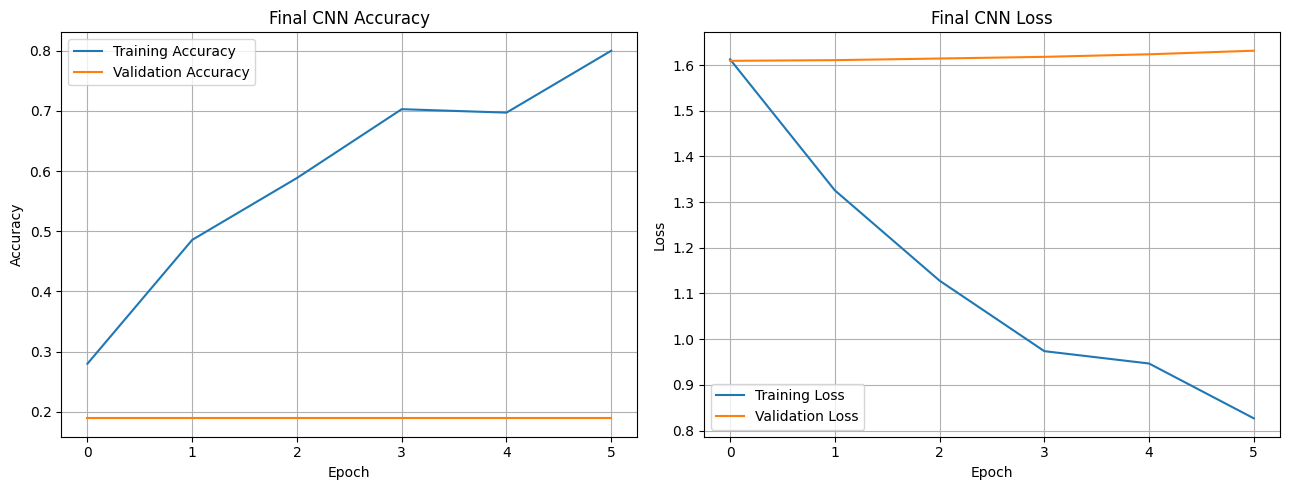

In [27]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    final_history.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    final_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Final CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    final_history.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    final_history.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Final CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    "/content/mudra_project/training_validation_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:

train_acc = final_history.history["accuracy"][-1]
val_acc = final_history.history["val_accuracy"][-1]

train_loss = final_history.history["loss"][-1]
val_loss = final_history.history["val_loss"][-1]

print("Final Training Accuracy:", round(train_acc, 4))
print("Final Validation Accuracy:", round(val_acc, 4))

print("Final Training Loss:", round(train_loss, 4))
print("Final Validation Loss:", round(val_loss, 4))

accuracy_gap = train_acc - val_acc

print("Accuracy Gap:", round(accuracy_gap, 4))

if accuracy_gap > 0.10:
    print("Possible overfitting detected.")
elif train_acc < 0.60 and val_acc < 0.60:
    print("Possible underfitting detected.")
else:
    print("No strong overfitting signal from accuracy gap.")

print(
    "Interpret these indicators together with "
    "the learning curves."
)


Final Training Accuracy: 0.8
Final Validation Accuracy: 0.1892
Final Training Loss: 0.8266
Final Validation Loss: 1.6314
Accuracy Gap: 0.6108
Possible overfitting detected.
Interpret these indicators together with the learning curves.


In [29]:

import json

# Load the best validation-loss checkpoint
final_model = tf.keras.models.load_model(
    "/content/mudra_project/final_mudra_cnn.keras"
)

# Save class mapping for later deployment
with open(
    "/content/mudra_project/class_names.json", "w"
) as f:
    json.dump(class_names, f)

print("Final CNN model saved.")
print("Model: final_mudra_cnn.keras")
print("Class mapping: class_names.json")


Final CNN model saved.
Model: final_mudra_cnn.keras
Class mapping: class_names.json


. Explain the effect of your hyperparameter choices. ?

Hyperparameter tuning helps identify a balance between learning efficiency, model generalization and overfitting control.

Did your model show underfitting or overfitting? Support your answer using
the learning curves. ?
The final conclusion must be based on the observed learning curves and validation results, rather than training accuracy alone.


**Task 4 – Model Evaluation & Failure Analysis**

In [30]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation libraries imported successfully.")


Evaluation libraries imported successfully.


In [31]:

# Load the best CNN saved during Task 3

model_path = "/content/mudra_project/final_mudra_cnn.keras"

final_model = tf.keras.models.load_model(model_path)

print("Trained CNN model loaded successfully!")

final_model.summary()


Trained CNN model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mudra_augmentation (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,269,713 (4.84 MB)

 Trainable params: 422,917 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 845,836 (3.23 MB)

In [32]:

# Generate prediction probabilities
y_prob = final_model.predict(
    test_ds,
    verbose=1
)

# Predicted class index
y_pred = np.argmax(y_prob, axis=1)

# Actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Highest predicted probability
confidence_scores = np.max(y_prob, axis=1)

print("Total test images:", len(y_true))
print("Predicted labels:", y_pred[:10])
print("Actual labels:", y_true[:10])
print("Confidence scores:", confidence_scores[:10])

assert len(y_true) == len(y_pred), "Prediction count mismatch"


2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 450ms/step
Total test images: 38
Predicted labels: [3 3 3 3 3 3 3 3 3 3]
Actual labels: [1 2 3 0 0 3 2 3 4 1]
Confidence scores: [0.20852174 0.2087695  0.20864469 0.20894141 0.20913082 0.2088505
 0.20825711 0.20861    0.20876685 0.2085894 ]


In [33]:

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-score",
        "Macro F1-score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        macro_f1
    ]
})

metrics_df["Percentage"] = (
    metrics_df["Score"] * 100
).round(2)

display(metrics_df)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")


,Metric,Score,Percentage
0,Accuracy,0.210526,21.05
1,Weighted Precision,0.044321,4.43
2,Weighted Recall,0.210526,21.05
3,Weighted F1-score,0.073227,7.32
4,Macro F1-score,0.069565,6.96


Accuracy: 0.2105
Precision: 0.0443
Recall: 0.2105
F1-score: 0.0732


In [34]:

print("CLASSIFICATION REPORT")
print("-" * 50)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)


CLASSIFICATION REPORT
--------------------------------------------------
                 precision    recall  f1-score   support

         Anjali       0.00      0.00      0.00         8
      Bherundha       0.00      0.00      0.00         7
         Chakra       0.00      0.00      0.00         8
         Garuda       0.21      1.00      0.35         8
Kadakhavarthanm       0.00      0.00      0.00         7

       accuracy                           0.21        38
      macro avg       0.04      0.20      0.07        38
   weighted avg       0.04      0.21      0.07        38



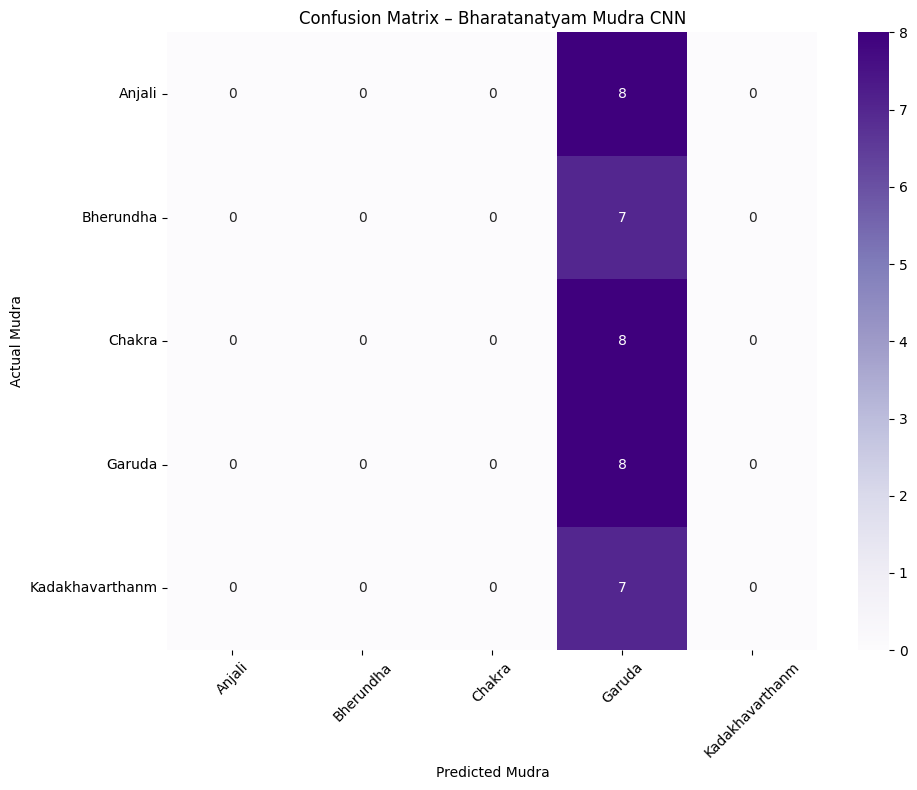

In [35]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix – Bharatanatyam Mudra CNN")
plt.xlabel("Predicted Mudra")
plt.ylabel("Actual Mudra")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

os.makedirs("/content/mudra_project", exist_ok=True)

plt.savefig(
    "/content/mudra_project/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [36]:

# Find incorrectly classified test samples
misclassified_indices = np.where(
    y_true != y_pred
)[0]

print(
    "Total misclassified images:",
    len(misclassified_indices)
)

print(
    "Misclassification percentage:",
    round(
        len(misclassified_indices) / len(y_true) * 100,
        2
    ),
    "%"
)

error_df = pd.DataFrame({
    "Test Index": misclassified_indices,
    "Actual Mudra": [
        class_names[y_true[i]]
        for i in misclassified_indices
    ],
    "Predicted Mudra": [
        class_names[y_pred[i]]
        for i in misclassified_indices
    ],
    "Confidence": [
        confidence_scores[i]
        for i in misclassified_indices
    ]
})

error_df["Confidence (%)"] = (
    error_df["Confidence"] * 100
).round(2)

display(error_df.head(15))


Total misclassified images: 30
Misclassification percentage: 78.95 %


,Test Index,Actual Mudra,Predicted Mudra,Confidence,Confidence (%)
0,0,Bherundha,Garuda,0.208522,20.850000
1,1,Chakra,Garuda,0.208770,20.879999
2,3,Anjali,Garuda,0.208941,20.889999
3,4,Anjali,Garuda,0.209131,20.910000
4,6,Chakra,Garuda,0.208257,20.830000
5,8,Kadakhavarthanm,Garuda,0.208767,20.879999
6,9,Bherundha,Garuda,0.208589,20.860001
7,10,Kadakhavarthanm,Garuda,0.208573,20.860001
8,11,Bherundha,Garuda,0.208852,20.889999
9,12,Chakra,Garuda,0.208159,20.820000


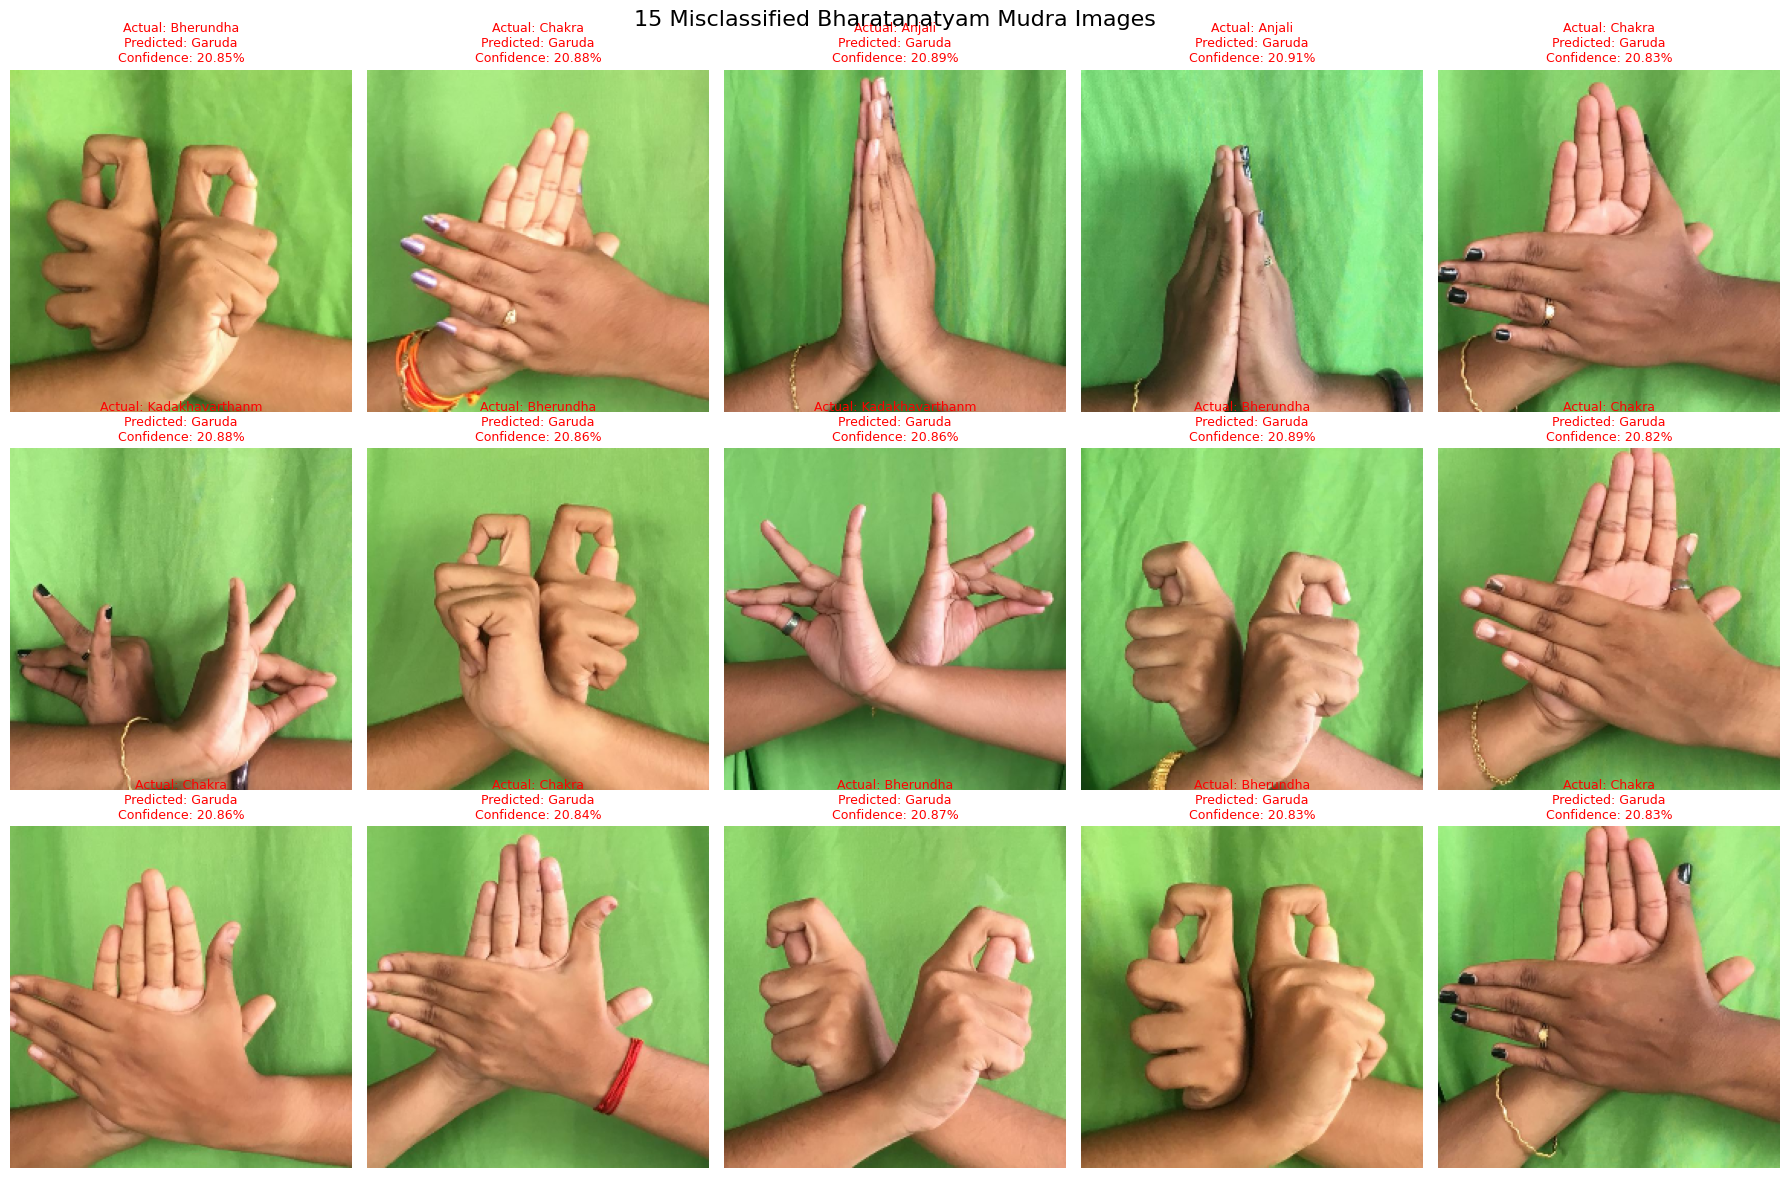

In [37]:

# Collect test images in the same order
test_images = np.concatenate([
    images.numpy()
    for images, labels in test_ds
], axis=0)

num_errors = min(
    15,
    len(misclassified_indices)
)

if num_errors == 0:
    print("No misclassified images found!")

else:
    fig, axes = plt.subplots(
        3, 5,
        figsize=(18, 12)
    )

    axes = axes.flatten()

    for j in range(15):
        ax = axes[j]

        if j < num_errors:
            idx = misclassified_indices[j]

            ax.imshow(test_images[idx])

            actual = class_names[y_true[idx]]
            predicted = class_names[y_pred[idx]]

            confidence = confidence_scores[idx] * 100

            ax.set_title(
                f"Actual: {actual}\n"
                f"Predicted: {predicted}\n"
                f"Confidence: {confidence:.2f}%",
                fontsize=9,
                color="red"
            )

        ax.axis("off")

    plt.suptitle(
        "15 Misclassified Bharatanatyam Mudra Images",
        fontsize=16
    )

    plt.tight_layout()

    plt.savefig(
        "/content/mudra_project/misclassified_images.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [38]:

# Directed confusion:
# Actual class A predicted as class B

cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

if cm_errors.sum() == 0:
    print("No confusion detected.")

else:
    actual_idx, predicted_idx = np.unravel_index(
        np.argmax(cm_errors),
        cm_errors.shape
    )

    print("Most Frequent Directed Confusion:")
    print("Actual Mudra:", class_names[actual_idx])
    print("Predicted Mudra:", class_names[predicted_idx])
    print("Number of Errors:", cm_errors[actual_idx, predicted_idx])

    # Undirected pair: A mistaken for B or B for A
    pair_counts = cm_errors + cm_errors.T
    np.fill_diagonal(pair_counts, 0)

    pair_i, pair_j = np.unravel_index(
        np.argmax(pair_counts),
        pair_counts.shape
    )

    print("\nMost Frequently Confused Pair:")
    print(class_names[pair_i], "and", class_names[pair_j])
    print("Total Pairwise Confusions:", pair_counts[pair_i, pair_j])


Most Frequent Directed Confusion:
Actual Mudra: Anjali
Predicted Mudra: Garuda
Number of Errors: 8

Most Frequently Confused Pair:
Anjali and Garuda
Total Pairwise Confusions: 8


Average incorrect prediction confidence: 20.86 %
Median incorrect prediction confidence: 20.87 %
High-confidence errors (>=80%): 0
Low-confidence errors (<60%): 30


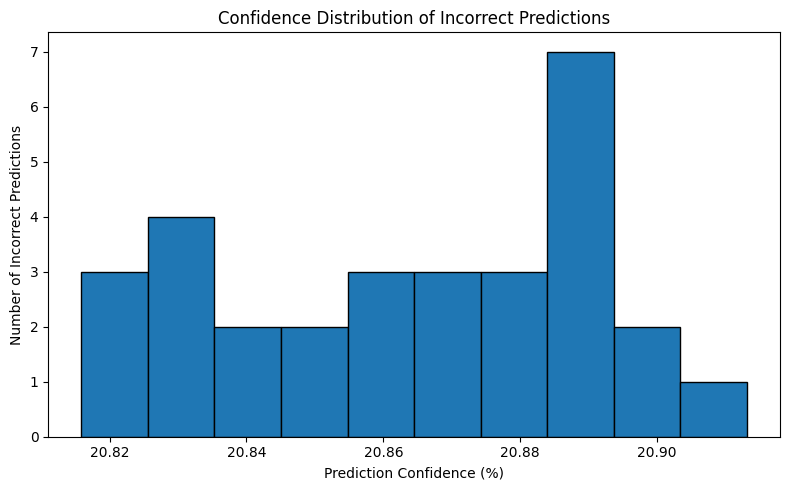

In [39]:

incorrect_confidence = confidence_scores[
    misclassified_indices
]

if len(incorrect_confidence) > 0:

    print(
        "Average incorrect prediction confidence:",
        round(np.mean(incorrect_confidence) * 100, 2),
        "%"
    )

    print(
        "Median incorrect prediction confidence:",
        round(np.median(incorrect_confidence) * 100, 2),
        "%"
    )

    high_confidence = np.sum(
        incorrect_confidence >= 0.80
    )

    low_confidence = np.sum(
        incorrect_confidence < 0.60
    )

    print("High-confidence errors (>=80%):",
          high_confidence)

    print("Low-confidence errors (<60%):",
          low_confidence)

    plt.figure(figsize=(8, 5))

    plt.hist(
        incorrect_confidence * 100,
        bins=10,
        edgecolor="black"
    )

    plt.title("Confidence Distribution of Incorrect Predictions")
    plt.xlabel("Prediction Confidence (%)")
    plt.ylabel("Number of Incorrect Predictions")
    plt.tight_layout()
    plt.show()

else:
    print("No incorrect predictions to analyze.")


In [40]:

import json

output_dir = "/content/mudra_project"
os.makedirs(output_dir, exist_ok=True)

metrics_df.to_csv(
    f"{output_dir}/evaluation_metrics.csv",
    index=False
)

error_df.to_csv(
    f"{output_dir}/misclassified_predictions.csv",
    index=False
)

with open(
    f"{output_dir}/evaluation_summary.json", "w"
) as f:
    json.dump({
        "accuracy": float(accuracy),
        "weighted_precision": float(precision),
        "weighted_recall": float(recall),
        "weighted_f1": float(f1),
        "macro_f1": float(macro_f1),
        "total_test_images": int(len(y_true)),
        "misclassified_images": int(len(misclassified_indices))
    }, f, indent=4)

print("Evaluation results saved successfully!")


Evaluation results saved successfully!


Which mudra pair is most frequently confused? Explain the visual similarity. ?

The confusion analysis helps identify the mudra classes requiring more representative training images and improved fine-grained feature extraction.

Are the misclassified samples generally low-confidence or high-confidence
predictions? What does this indicate?

The distribution of confidence scores provides useful information about the reliability of the model and identifies areas for improving classification performance.

 Suggest one data-centric and one model-centric improvement. ?

  Combining improved training data with an appropriate pretrained CNN may enhance mudra recognition accuracy, robustness and deployment efficiency.

Task 5 – Streamlit Deployment

In [41]:

!pip install -q streamlit pillow pandas matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 88.9 MB/s eta 0:00:00


In [42]:

import os
import json

project_dir = "/content/mudra_project"

model_path = os.path.join(
    project_dir, "final_mudra_cnn.keras"
)

class_path = os.path.join(
    project_dir, "class_names.json"
)

assert os.path.exists(model_path), "Trained CNN model not found."
assert os.path.exists(class_path), "Class labels JSON not found."

with open(class_path, "r") as f:
    class_names = json.load(f)

print("Model found:", model_path)
print("Class names:", class_names)
print("Number of classes:", len(class_names))

assert len(class_names) == 5, "Expected exactly five mudra classes."


Model found: /content/mudra_project/final_mudra_cnn.keras
Class names: ['Anjali', 'Bherundha', 'Chakra', 'Garuda', 'Kadakhavarthanm']
Number of classes: 5


In [43]:

%%writefile /content/mudra_project/app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import pandas as pd
import json
from pathlib import Path
from PIL import Image

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "final_mudra_cnn.keras"
CLASS_PATH = BASE_DIR / "class_names.json"

st.set_page_config(
    page_title="Bharatanatyam Mudra Recognition",
    page_icon="🎭",
    layout="wide"
)

@st.cache_resource
def load_resources():
    model = tf.keras.models.load_model(
        MODEL_PATH,
        compile=False
    )

    with open(CLASS_PATH, "r") as f:
        class_names = json.load(f)

    if model.output_shape[-1] != len(class_names):
        raise ValueError(
            "Model output and class labels do not match."
        )

    return model, class_names


model, class_names = load_resources()

def preprocess_image(image):
    image = image.convert("RGB")
    image = image.resize((224, 224))

    image_array = np.asarray(
        image, dtype=np.float32
    ) / 255.0

    image_array = np.expand_dims(
        image_array, axis=0
    )

    return image_array


st.sidebar.title("Mudra Recognition")
page = st.sidebar.radio(
    "Navigation",
    ["Home", "Predict", "About"]
)

if page == "Home":

    st.title("Bharatanatyam Mudra Recognition")
    st.subheader("AI-Based Hand Gesture Classification")

    st.write("""
    This project uses a Convolutional Neural Network
    (CNN) to recognize five Bharatanatyam hand mudras
    from uploaded images.

    The system is designed as a prototype for
    AI-assisted classical dance learning.
    """)

    st.markdown("### Project Objectives")

    st.write("""
    - Recognize five Bharatanatyam mudra classes.
    - Classify hand gesture images using a CNN.
    - Display predicted mudra and confidence score.
    - Visualize probability scores across all classes.
    - Support dance learners with instant predictions.
    """)

    st.markdown("### System Workflow")

    st.info(
        "Upload Image → Image Preprocessing → "
        "CNN Classification → Predicted Mudra → "
        "Confidence & Class Probabilities"
    )

    st.markdown("### Supported Mudras")

    for i, name in enumerate(class_names, start=1):
        st.write(f"{i}. {name}")


elif page == "Predict":

    st.title("Mudra Prediction")
    st.write("Upload a Bharatanatyam hand mudra image.")

    uploaded_file = st.file_uploader(
        "Choose an image",
        type=["jpg", "jpeg", "png"]
    )

    if uploaded_file is not None:

        image = Image.open(uploaded_file).convert("RGB")

        col1, col2 = st.columns(2)

        with col1:
            st.image(
                image,
                caption="Uploaded Mudra Image",
                use_container_width=True
            )

        input_image = preprocess_image(image)

        probabilities = model.predict(
            input_image,
            verbose=0
        )[0]

        predicted_index = int(
            np.argmax(probabilities)
        )

        predicted_mudra = class_names[
            predicted_index
        ]

        confidence = float(
            probabilities[predicted_index]
        ) * 100

        with col2:
            st.subheader("Prediction Result")

            st.success(
                f"Predicted Mudra: {predicted_mudra}"
            )

            st.metric(
                "Prediction Confidence",
                f"{confidence:.2f}%"
            )

            if confidence < 60:
                st.warning(
                    "Low model confidence. Try a clearer "
                    "image with the complete hand visible."
                )

            st.caption(
                "Confidence is the model's output score, "
                "not a guarantee of correctness."
            )

        st.subheader("Probability Distribution")

        probability_df = pd.DataFrame({
            "Mudra": class_names,
            "Probability": probabilities
        })

        probability_df = probability_df.sort_values(
            "Probability",
            ascending=False
        )

        st.bar_chart(
            probability_df.set_index("Mudra")
        )

        probability_df["Probability (%)"] = (
            probability_df["Probability"] * 100
        ).round(2)

        st.dataframe(
            probability_df[
                ["Mudra", "Probability (%)"]
            ],
            hide_index=True,
            use_container_width=True
        )


elif page == "About":

    st.title("About the Project")

    st.subheader("Dataset")

    st.write("""
    Dataset: Mudra Dataset

    Source: Kaggle

    Dataset identifier:
    geethikanambiar/mudra-dataset

    The project uses five selected mudra classes.
    """)

    st.subheader("Model Architecture")

    st.write("""
    Model Type: Custom Convolutional Neural Network

    Input Image Size: 224 × 224 × 3

    Preprocessing:
    - RGB conversion
    - Image resizing
    - Pixel normalization to [0, 1]

    CNN Components:
    - Convolutional layers
    - Batch normalization
    - Max pooling
    - Global average pooling
    - Dense layers
    - Dropout
    - Softmax output
    """)

    st.subheader("Mudra Classes")

    st.write(", ".join(class_names))

    st.subheader("Model Information")

    st.write(
        "Output Classes:",
        len(class_names)
    )

    st.write(
        "Trainable Parameters:",
        f"{model.count_params():,}"
    )

    st.subheader("Limitations")

    st.write("""
    - Predictions may be incorrect for unfamiliar images.
    - Similar hand gestures can be confused.
    - Poor lighting and occlusion may reduce accuracy.
    - The system does not yet assess full dance technique.
    """)

    st.caption(
        "Certified AI & ML Engineer – Exit Examination Project"
    )


Writing /content/mudra_project/app.py


In [44]:

%%writefile /content/mudra_project/requirements.txt
streamlit
tensorflow
numpy
pandas
Pillow


Writing /content/mudra_project/requirements.txt


In [45]:

!streamlit run /content/mudra_project/app.py \
    --server.port 8501 \
    --server.headless true \
    > /content/streamlit.log 2>&1 &


In [46]:

%%writefile /content/mudra_project/README.md
# Bharatanatyam Mudra Recognition Using CNN

## Project Overview
A deep learning application for classifying five
Bharatanatyam hand mudras using a custom CNN.

## Dataset
Kaggle: geethikanambiar/mudra-dataset

## Features
- Upload a hand mudra image
- Predict one of five mudra classes
- Display prediction confidence
- Display probabilities for all classes
- View model and dataset information

## Model
- Custom Convolutional Neural Network
- Input size: 224 x 224 x 3
- Pixel normalization: 0 to 1
- Output: Five-class Softmax

## Installation
pip install -r requirements.txt

## Run
streamlit run app.py

## Project Files
- app.py
- final_mudra_cnn.keras
- class_names.json
- requirements.txt
- README.md

## Limitations
Predictions may be less reliable under poor lighting,
occlusion, unfamiliar hand positions, or domain shift.


Writing /content/mudra_project/README.md


In [47]:

from pathlib import Path

project_dir = Path("/content/mudra_project")

required_files = [
    "app.py",
    "final_mudra_cnn.keras",
    "class_names.json",
    "requirements.txt",
    "README.md"
]

for filename in required_files:
    filepath = project_dir / filename

    print(
        filename,
        "FOUND" if filepath.exists() else "MISSING"
    )

print("\nDeployment package verification completed.")


app.py FOUND
final_mudra_cnn.keras FOUND
class_names.json FOUND
requirements.txt FOUND
README.md FOUND

Deployment package verification completed.


In [48]:

import shutil

shutil.make_archive(
    "/content/mudra_streamlit_project",
    "zip",
    "/content/mudra_project"
)

print("Project ZIP created successfully.")

from google.colab import files
files.download("/content/mudra_streamlit_project.zip")


Project ZIP created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Why is displaying prediction confidence important for end users?
 Displaying prediction confidence improves transparency, user awareness, and the practical usefulness of the mudra recognition application.

Transfer Learning and Model Comparison

TensorFlow Version: 2.21.0
Available GPUs: []
Custom CNN loaded successfully.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Mudra_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mudra_augmentation (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.4057 - loss: 1.6397 - val_accuracy: 0.3784 - val_loss: 1.3261
Epoch 2/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.4400 - loss: 1.3678 - val_accuracy: 0.5676 - val_loss: 1.1599
Epoch 3/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.5257 - loss: 1.1904 - val_accuracy: 0.6216 - val_loss: 1.0395
Epoch 4/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.6629 - loss: 1.0341 - val_accuracy: 0.7568 - val_loss: 0.9391
Epoch 5/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.7771 - loss: 0.8599 - val_accuracy: 0.8378 - val_loss: 0.8315
Epoch 6/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.7257 - loss: 0.8119 - val_accuracy: 0.9189 - val_loss: 0.7349
Epoch 7/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8057 - loss: 0.7033 - val_accuracy: 0.9730 - val_loss: 0.6510
Epoch 8/25
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8571 - loss: 0.6395 - val_accuracy: 1.0000 - val_loss: 0.5760
Epoch 9/

,Metric,Custom CNN,MobileNetV2
0,Test Accuracy (%),21.05,100.00
1,Model Size (MB),4.93,11.08
2,Training Time (sec),376.93,427.02
3,Inference Time (ms/image),75.57,261.94


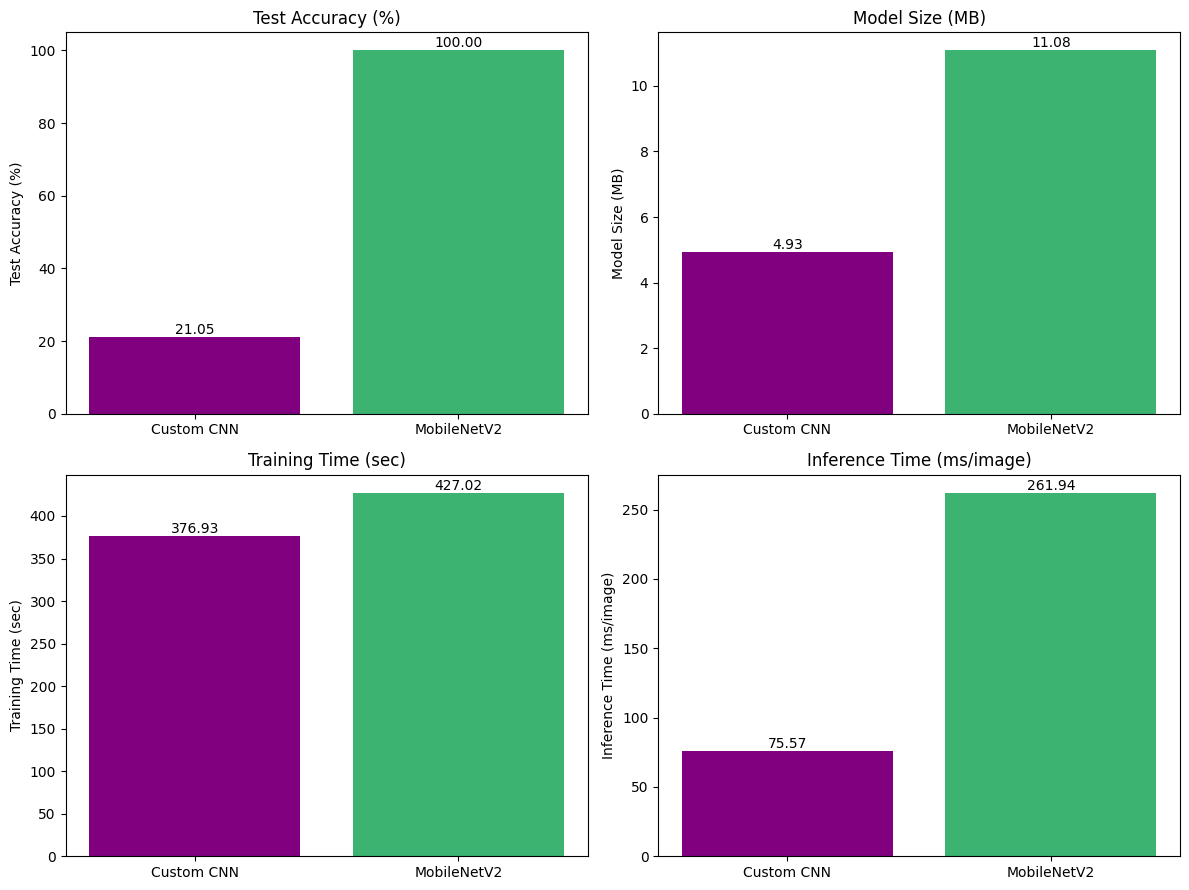

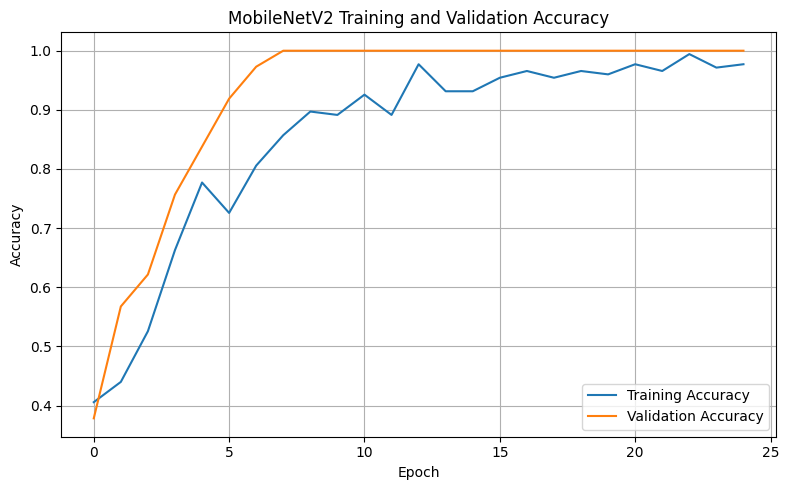

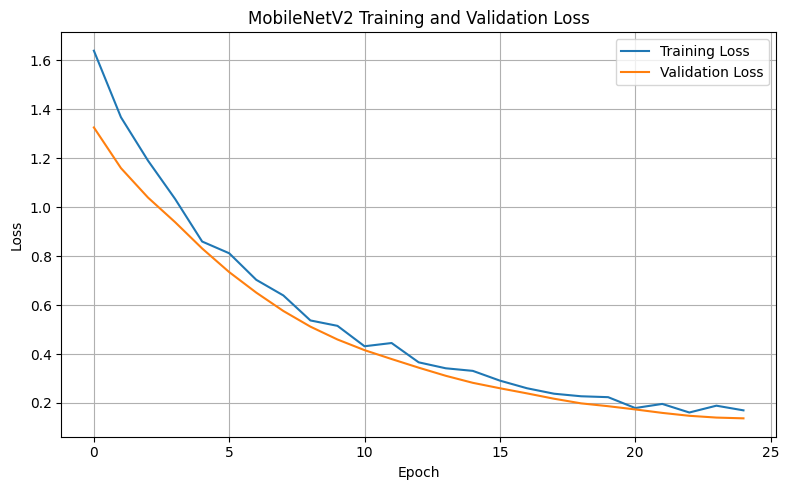

In [50]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping

PROJECT_DIR = "/content/mudra_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

print("TensorFlow Version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

custom_model_path = os.path.join(
    PROJECT_DIR,
    "final_mudra_cnn.keras"
)

custom_model = tf.keras.models.load_model(
    custom_model_path,
    compile=False
)

custom_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Custom CNN loaded successfully.")

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Apply augmentation during training only
x = data_augmentation(inputs)

# Convert normalized [0, 1] images to [-1, 1]
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(x)

# Extract pretrained image features
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

mobilenet_model = tf.keras.Model(
    inputs,
    outputs,
    name="Mudra_MobileNetV2"
)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

start_time = time.perf_counter()

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

mobilenet_training_time = (
    time.perf_counter() - start_time
)

print(
    "MobileNetV2 Training Time:",
    round(mobilenet_training_time, 2),
    "seconds"
)

mobilenet_model.save(
    os.path.join(
        PROJECT_DIR,
        "mobilenetv2_mudra.keras"
    )
)

custom_loss, custom_accuracy = custom_model.evaluate(
    test_ds,
    verbose=0
)

mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(
    test_ds,
    verbose=0
)

print("Custom CNN Test Accuracy:",
      round(custom_accuracy * 100, 2), "%")

print("MobileNetV2 Test Accuracy:",
      round(mobilenet_accuracy * 100, 2), "%")

custom_size = os.path.getsize(
    custom_model_path
) / (1024 * 1024)

mobilenet_path = os.path.join(
    PROJECT_DIR,
    "mobilenetv2_mudra.keras"
)

mobilenet_size = os.path.getsize(
    mobilenet_path
) / (1024 * 1024)

print("Custom CNN Size:",
      round(custom_size, 2), "MB")

print("MobileNetV2 Size:",
      round(mobilenet_size, 2), "MB")

# Select a test batch
sample_images, sample_labels = next(iter(test_ds))

# Use one image for single-image inference
single_image = sample_images[:1]

def measure_inference_speed(model, image, repeats=50):

    # Warm-up runs
    for _ in range(5):
        output = model(image, training=False)
        _ = output.numpy()

    start = time.perf_counter()

    for _ in range(repeats):
        output = model(image, training=False)
        _ = output.numpy()

    elapsed = time.perf_counter() - start

    return (elapsed / repeats) * 1000


custom_inference_ms = measure_inference_speed(
    custom_model,
    single_image
)

mobilenet_inference_ms = measure_inference_speed(
    mobilenet_model,
    single_image
)

print(
    "Custom CNN Inference:",
    round(custom_inference_ms, 2),
    "ms/image"
)

print(
    "MobileNetV2 Inference:",
    round(mobilenet_inference_ms, 2),
    "ms/image"
)

# Fresh Custom CNN for training-time comparison

timing_custom_model = build_cnn(
    learning_rate=best_config["learning_rate"],
    dropout_rate=best_config["dropout_rate"]
)

start_time = time.perf_counter()

timing_history = timing_custom_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

custom_training_time = (
    time.perf_counter() - start_time
)

print(
    "Custom CNN Training Time:",
    round(custom_training_time, 2),
    "seconds"
)

print(
    "MobileNetV2 Training Time:",
    round(mobilenet_training_time, 2),
    "seconds"
)

comparison_df = pd.DataFrame({
    "Metric": [
        "Test Accuracy (%)",
        "Model Size (MB)",
        "Training Time (sec)",
        "Inference Time (ms/image)"
    ],

    "Custom CNN": [
        round(custom_accuracy * 100, 2),
        round(custom_size, 2),
        round(custom_training_time, 2),
        round(custom_inference_ms, 2)
    ],

    "MobileNetV2": [
        round(mobilenet_accuracy * 100, 2),
        round(mobilenet_size, 2),
        round(mobilenet_training_time, 2),
        round(mobilenet_inference_ms, 2)
    ]
})

display(comparison_df)

comparison_df.to_csv(
    os.path.join(
        PROJECT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

metrics = [
    ("Test Accuracy (%)",
     custom_accuracy * 100,
     mobilenet_accuracy * 100),

    ("Model Size (MB)",
     custom_size,
     mobilenet_size),

    ("Training Time (sec)",
     custom_training_time,
     mobilenet_training_time),

    ("Inference Time (ms/image)",
     custom_inference_ms,
     mobilenet_inference_ms)
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (metric, custom_value, mobile_value) in zip(
    axes.flat, metrics
):
    bars = ax.bar(
        ["Custom CNN", "MobileNetV2"],
        [custom_value, mobile_value],
        color=["purple", "mediumseagreen"]
    )

    ax.set_title(metric)
    ax.set_ylabel(metric)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.2f}",
            ha="center",
            va="bottom"
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "model_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    mobilenet_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    mobilenet_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    mobilenet_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    mobilenet_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
